NASA C-MAPSS RUL Prediction
----
Predicting the Remaining Useful Life (RUL) of turbofan engines from sensor data, using the FD001 subset of NASA's Commercial Modular Aero-Propulsion System Simulation (C-MAPSS) dataset.

In [1]:
# Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
# Adding columns names and sensor numbers w.r.t the table 2 from paper
column_names = ['unit_number', 'time_cycle', 'op_setting_1', 'op_setting_2', 'op_setting_3'] + [f's{i}' for i in range(1, 22)]

df = pd.read_csv('../data/train_FD001.txt', sep=' ', header=None)
df = df.iloc[:, :26]   # keep only the first 26 real columns, drop the 2 empties
df.columns = column_names
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20631 entries, 0 to 20630
Data columns (total 26 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   unit_number   20631 non-null  int64  
 1   time_cycle    20631 non-null  int64  
 2   op_setting_1  20631 non-null  float64
 3   op_setting_2  20631 non-null  float64
 4   op_setting_3  20631 non-null  float64
 5   s1            20631 non-null  float64
 6   s2            20631 non-null  float64
 7   s3            20631 non-null  float64
 8   s4            20631 non-null  float64
 9   s5            20631 non-null  float64
 10  s6            20631 non-null  float64
 11  s7            20631 non-null  float64
 12  s8            20631 non-null  float64
 13  s9            20631 non-null  float64
 14  s10           20631 non-null  float64
 15  s11           20631 non-null  float64
 16  s12           20631 non-null  float64
 17  s13           20631 non-null  float64
 18  s14           20631 non-null  float64

# Data pre-processing and EDA
----

In [3]:
# getting the cycle number (max cycle) where that unit failed

df['max_cycle'] = df.groupby('unit_number')['time_cycle'].transform('max')

df.head()

,unit_number,time_cycle,op_setting_1,op_setting_2,op_setting_3,s1,s2,s3,s4,s5,...,s13,s14,s15,s16,s17,s18,s19,s20,s21,max_cycle
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,192
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,192
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,192
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,192
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,192


In [4]:
# Calculating the RUL by subtracting the max_cycle with current cycle

df['RUL'] = df['max_cycle'] - df['time_cycle']
df.tail()

,unit_number,time_cycle,op_setting_1,op_setting_2,op_setting_3,s1,s2,s3,s4,s5,...,s14,s15,s16,s17,s18,s19,s20,s21,max_cycle,RUL
20626,100,196,-0.0004,-0.0003,100.0,518.67,643.49,1597.98,1428.63,14.62,...,8137.60,8.4956,0.03,397,2388,100.0,38.49,22.9735,200,4
20627,100,197,-0.0016,-0.0005,100.0,518.67,643.54,1604.50,1433.58,14.62,...,8136.50,8.5139,0.03,395,2388,100.0,38.30,23.1594,200,3
20628,100,198,0.0004,0.0000,100.0,518.67,643.42,1602.46,1428.18,14.62,...,8141.05,8.5646,0.03,398,2388,100.0,38.44,22.9333,200,2
20629,100,199,-0.0011,0.0003,100.0,518.67,643.23,1605.26,1426.53,14.62,...,8139.29,8.5389,0.03,395,2388,100.0,38.29,23.0640,200,1
20630,100,200,-0.0032,-0.0005,100.0,518.67,643.85,1600.38,1432.14,14.62,...,8137.33,8.5036,0.03,396,2388,100.0,38.37,23.0522,200,0


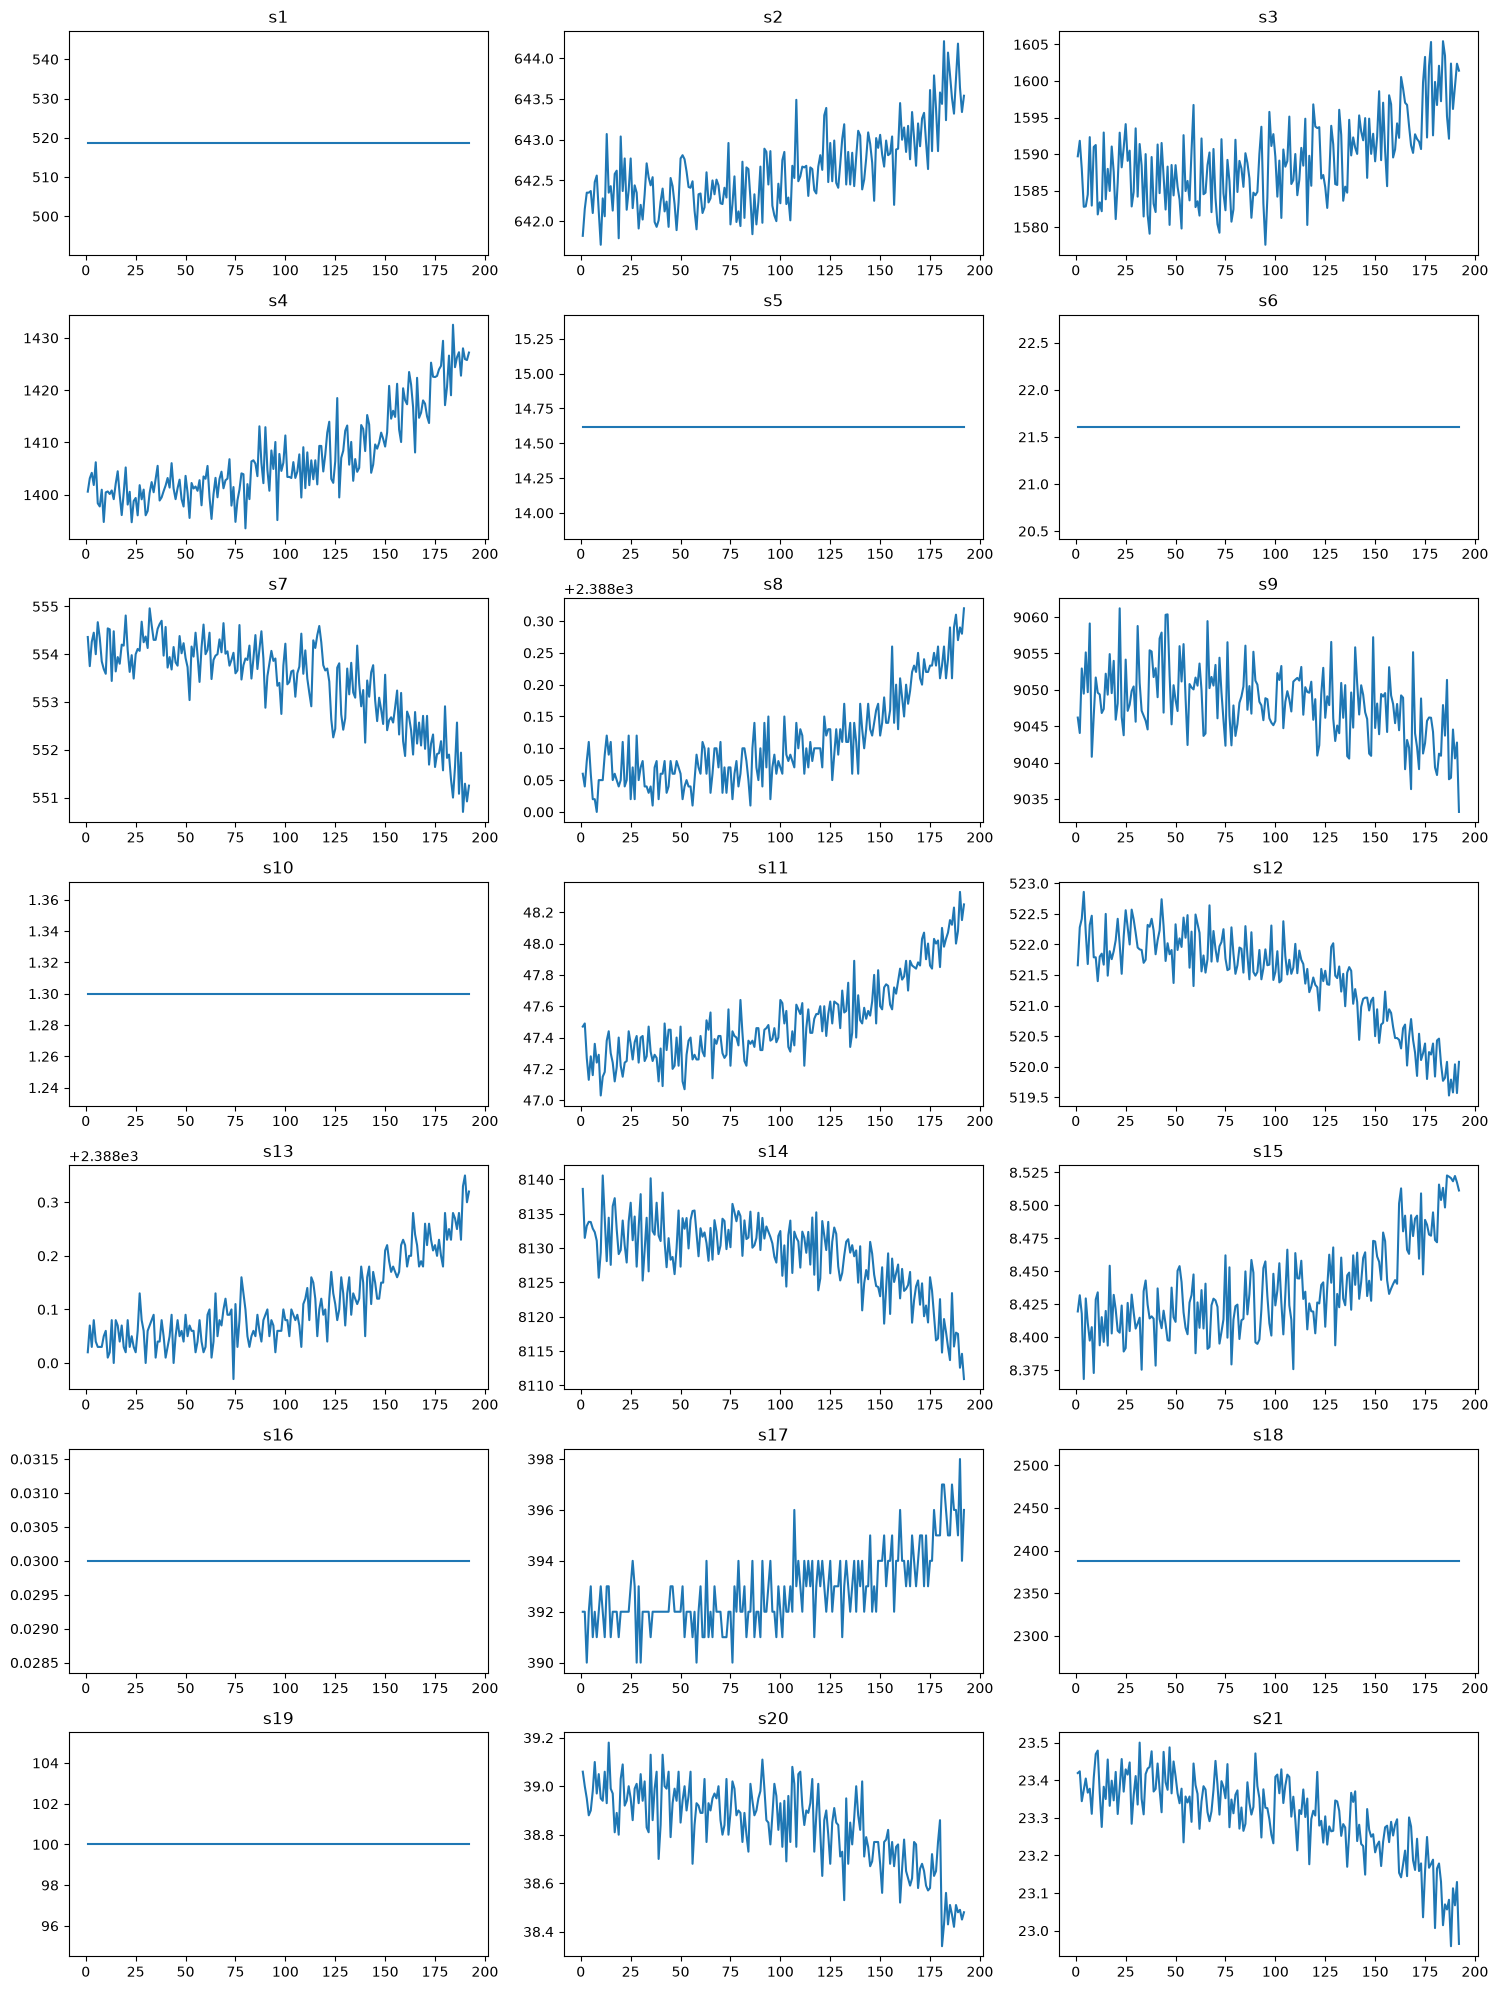

In [5]:
# Getting all the sensor columns to plot the graphs
sensor_cols = [f's{i}' for i in range(1, 22)]  # s1 to s21

# Extracting only the engine one data for plot.
plot_engine1 = df.loc[df['unit_number'] == 1].copy()

# Plotting multiple graphs
fig, ax = plt.subplots(7, 3, figsize=(15, 20))  # 7 rows x 3 cols = 21 slots
ax = ax.flatten()  # turns the 2D grid into a flat list so you can index it 0-20

# Looping over each sensor readings
for i, sensor in enumerate(sensor_cols):
    ax[i].plot(plot_engine1['time_cycle'], plot_engine1[sensor])
    ax[i].set_title(sensor)

plt.tight_layout()  # prevents subplot titles/labels from overlapping
plt.show()

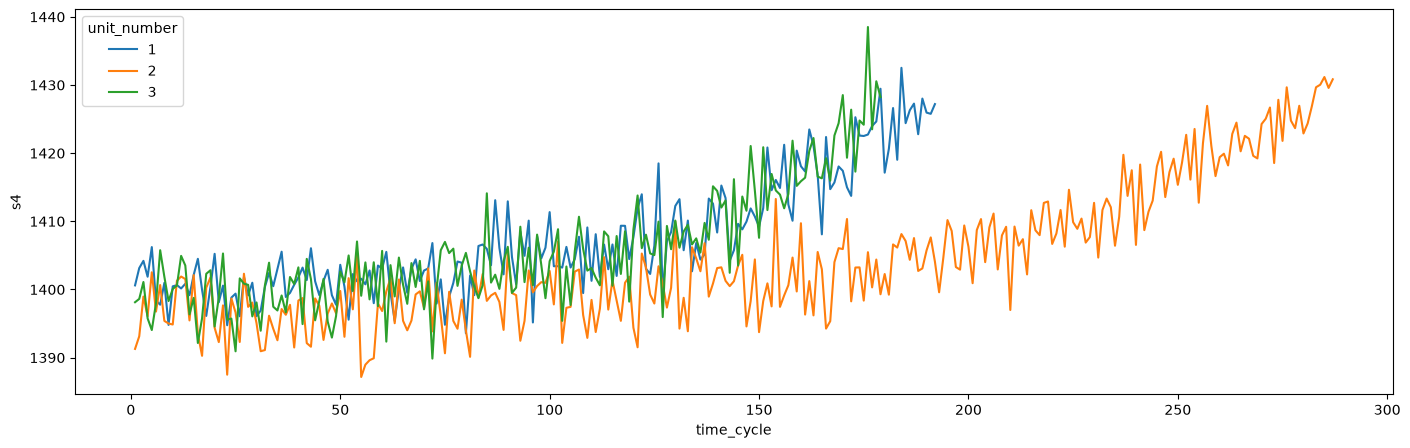

In [6]:
# Plotting s4 of set engines to understand trend
engines_set = np.arange(1,4)

engine_set_df = df[df['unit_number'].isin(engines_set)].copy() # adding .copy() to avoid slicing warning
engine_set_df['unit_number'] = engine_set_df['unit_number'].astype(str) # Changing the dtype to str as sns consider this value as continuous variable

plt.figure(figsize=(17,5))
sns.lineplot(engine_set_df, x='time_cycle', y='s4', hue='unit_number')

plt.show()

In [7]:
# Dropping the sensors that are flat and can;t be used for training

sensor_drop = ['s1', 's5', 's6', 's10', 's16', 's18', 's19']
df = df.drop(columns= sensor_drop)
df.head()

,unit_number,time_cycle,op_setting_1,op_setting_2,op_setting_3,s2,s3,s4,s7,s8,...,s11,s12,s13,s14,s15,s17,s20,s21,max_cycle,RUL
0,1,1,-0.0007,-0.0004,100.0,641.82,1589.70,1400.60,554.36,2388.06,...,47.47,521.66,2388.02,8138.62,8.4195,392,39.06,23.4190,192,191
1,1,2,0.0019,-0.0003,100.0,642.15,1591.82,1403.14,553.75,2388.04,...,47.49,522.28,2388.07,8131.49,8.4318,392,39.00,23.4236,192,190
2,1,3,-0.0043,0.0003,100.0,642.35,1587.99,1404.20,554.26,2388.08,...,47.27,522.42,2388.03,8133.23,8.4178,390,38.95,23.3442,192,189
3,1,4,0.0007,0.0000,100.0,642.35,1582.79,1401.87,554.45,2388.11,...,47.13,522.86,2388.08,8133.83,8.3682,392,38.88,23.3739,192,188
4,1,5,-0.0019,-0.0002,100.0,642.37,1582.85,1406.22,554.00,2388.06,...,47.28,522.19,2388.04,8133.80,8.4294,393,38.90,23.4044,192,187


In [8]:
# checking shape and columns after dropping

print(df.shape)
print(df.columns.tolist())

(20631, 21)
['unit_number', 'time_cycle', 'op_setting_1', 'op_setting_2', 'op_setting_3', 's2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21', 'max_cycle', 'RUL']


In [9]:
# Checking if the operational setting are useful for model training
df[['op_setting_1','op_setting_2','op_setting_3']].describe()

,op_setting_1,op_setting_2,op_setting_3
count,20631.000000,20631.000000,20631.0
mean,-0.000009,0.000002,100.0
std,0.002187,0.000293,0.0
min,-0.008700,-0.000600,100.0
25%,-0.001500,-0.000200,100.0
50%,0.000000,0.000000,100.0
75%,0.001500,0.000300,100.0
max,0.008700,0.000600,100.0


In [10]:
# check point to save the df

raw_df = df.copy()

In [11]:
# Retrieving the df checkpoint from raw df.

#df = raw_df.copy()

# Train/Val split
----

In [12]:
# Train/Val split

from sklearn.model_selection import train_test_split

# Extracting all engine IDs
engine_IDs = df['unit_number'].unique()

# Splitting the training and validation engine sets based on their IDs
train_engine_IDs, val_engine_IDs = train_test_split(engine_IDs, test_size= 0.2, random_state= 42)
#print(train_engine_IDs, val_engine_IDs)

#train_df = df[df['unit_number'].isin(train_engine_IDs)].copy()
#print(train_df['unit_number'].unique())
#val_df = df[df['unit_number'].isin(val_engine_IDs)].copy()
#print(val_df['unit_number'].unique())

In [13]:
#val_df.head()

# Rolling window
----

In [14]:
# Applying rolling windows on sensors
sensor_list = ['s2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']

# global df and window size for function
window_size = 5

# rolling window function that takes the df, sensor list and window size and returns rolled window df copy
def rolling_window(df, sensor_list, window_size):
    roll_window_df = df.copy()
    
    # looping sensor data to get mean and std 
    for s in sensor_list:
        roll_window_df[f"{s}_mean_{window_size}"] = roll_window_df.groupby('unit_number')[s].transform(lambda x: x.rolling(window_size).mean())
        roll_window_df[f'{s}_std_{window_size}'] = roll_window_df.groupby('unit_number')[s].transform(lambda x: x.rolling(window_size).std())
    
    return roll_window_df.copy()

# Getting the df after the rolling windows is applied
roll_window_df = rolling_window(df, sensor_list, 5)

# Splitting rolling windows train and val df using same train and val df split
roll_win_train_df = roll_window_df[roll_window_df['unit_number'].isin(train_engine_IDs)].copy()
roll_win_val_df = roll_window_df[roll_window_df['unit_number'].isin(val_engine_IDs)].copy()

In [15]:
# Checking the new sensor values
new_cols = [c for c in roll_window_df.columns if c.endswith(f'_{window_size}')]
print(len(new_cols))
print(roll_window_df[new_cols].isna().sum())

28
s2_mean_5     400
s2_std_5      400
s3_mean_5     400
s3_std_5      400
s4_mean_5     400
s4_std_5      400
s7_mean_5     400
s7_std_5      400
s8_mean_5     400
s8_std_5      400
s9_mean_5     400
s9_std_5      400
s11_mean_5    400
s11_std_5     400
s12_mean_5    400
s12_std_5     400
s13_mean_5    400
s13_std_5     400
s14_mean_5    400
s14_std_5     400
s15_mean_5    400
s15_std_5     400
s17_mean_5    400
s17_std_5     400
s20_mean_5    400
s20_std_5     400
s21_mean_5    400
s21_std_5     400
dtype: int64


In [16]:
# Dropping the NaN value from the rolling window dfs since our current modes doesn't take Nan (eg. Linear Regression)

# extracting all the new rolling window columns
roll_win_cols = [c for c in roll_window_df.columns if c.endswith(f'_{window_size}')]

# Dropping NaN from the training set
roll_win_train_feat = roll_win_train_df.dropna(subset = roll_win_cols).copy()
# Dropping NaN from the val set
roll_win_val_feat = roll_win_val_df.dropna(subset = roll_win_cols).copy()


In [17]:
# Using only sensor columns for scaling and excluding the below columns
exclude_sensor = ['unit_number', 'time_cycle', 'op_setting_1', 'op_setting_2', 'op_setting_3', 'max_cycle', 'RUL']

# rolling windows df containing only sensors
roll_win_train_sensor_df = roll_win_train_feat.drop(columns = exclude_sensor).copy()
roll_win_val_sensor_df = roll_win_val_feat.drop(columns = exclude_sensor).copy()

# Scaling
----

In [18]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

In [19]:
# Scaling the train df sensor columns

'''
We are assigning the scaled sensor columns back to the train df by passing the .columns of train_sensor_df
'''

# Scaling the train sensor features
roll_win_train_feat[roll_win_train_sensor_df.columns] = scaler.fit_transform(roll_win_train_sensor_df)

# Scaling the val sensor features
roll_win_val_feat[roll_win_val_sensor_df.columns] = scaler.transform(roll_win_val_sensor_df)

In [20]:
# clipping the RUL as till 125 cycles, the engine is not shown signs of degrading based on NASA/PHM08 challenge scoring (2008 paper by Frank Heimes)

roll_win_train_feat['RUL'] = roll_win_train_feat['RUL'].clip(upper = 125)
roll_win_val_feat['RUL'] = roll_win_val_feat['RUL'].clip(upper = 125)

In [21]:
roll_win_train_feat[roll_win_train_feat.columns].describe().loc[['mean', 'std']]


,unit_number,time_cycle,op_setting_1,op_setting_2,op_setting_3,s2,s3,s4,s7,s8,...,s14_mean_5,s14_std_5,s15_mean_5,s15_std_5,s17_mean_5,s17_std_5,s20_mean_5,s20_std_5,s21_mean_5,s21_std_5
mean,53.047780,111.483652,-0.000006,0.000002,100.0,4.164469e-14,9.717736e-15,9.568986e-15,-9.477986e-15,-5.554205e-12,...,4.878293e-14,-8.924987e-17,-2.392247e-14,-2.869996e-16,-3.072996e-15,-8.924987e-17,5.113493e-15,-4.549994e-17,-2.040497e-15,8.224988e-17
std,29.265614,68.671191,0.002193,0.000292,0.0,1.000031e+00,1.000031e+00,1.000031e+00,1.000031e+00,1.000031e+00,...,1.000031e+00,1.000031e+00,1.000031e+00,1.000031e+00,1.000031e+00,1.000031e+00,1.000031e+00,1.000031e+00,1.000031e+00,1.000031e+00


In [22]:
#val_df[val_sensor_df.columns].describe().loc[['mean', 'std']]

In [23]:
# Building feature sets for Test A/B
# Test A: Only the initial columns to reproduce the results from ver01
# Test B: Including the rolling windows columns of mean and std for ver02

# Training feature
# Test A
X_train_A = roll_win_train_feat.drop(columns= exclude_sensor + new_cols)
y_train_A = roll_win_train_feat['RUL']

# Test B
X_train_B = roll_win_train_feat.drop(columns= exclude_sensor)
y_train_B = roll_win_train_feat['RUL']

#  Validation target
# Test A
X_val_A = roll_win_val_feat.drop(columns= exclude_sensor + new_cols)
y_val_A = roll_win_val_feat['RUL']

#  Validation target
# Test B
X_val_B = roll_win_val_feat.drop(columns= exclude_sensor)
y_val_B = roll_win_val_feat['RUL']

In [24]:
# Based on most contributed features, the std columns are not contribution much.

# excluding the std columns
std_cols = [std for std in roll_window_df.columns if std.endswith(f'std_{window_size}')]
print(std_cols)

X_train_C = roll_win_train_feat.drop(columns= exclude_sensor + std_cols)
y_train_C = roll_win_train_feat['RUL']

X_val_C = roll_win_val_feat.drop(columns= exclude_sensor + std_cols)
y_val_C = roll_win_val_feat['RUL']

['s2_std_5', 's3_std_5', 's4_std_5', 's7_std_5', 's8_std_5', 's9_std_5', 's11_std_5', 's12_std_5', 's13_std_5', 's14_std_5', 's15_std_5', 's17_std_5', 's20_std_5', 's21_std_5']


In [25]:
print(len(X_train_C.columns))

28


# Linear Regression
----

In [26]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error

In [27]:
# Creating separate models for Test A/B

LR_model_A = LinearRegression()
LR_model_B = LinearRegression()

In [28]:
# Test A training
LR_model_A.fit(X_train_A, y_train_A)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](14,)","[-2.47,-1.86,-4.14,...,-1.98, 2.71, 2.62]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](14,)","['s2','s3','s4',...,'s17','s20','s21']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,86.21
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,14
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(14)


In [29]:
# Test B training
LR_model_B.fit(X_train_B, y_train_B)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](42,)","[-0.77,-0.5 ,-1.29,..., 0.33, 2.65, 0.5 ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](42,)","['s2','s3','s4',...,'s20_std_5','s21_mean_5','s21_std_5']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,86.21
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,42
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(42)


In [30]:
# Target prediction using the trained model

y_pred_A = LR_model_A.predict(X_val_A)
y_pred_B = LR_model_B.predict(X_val_B)

In [31]:
# Calculating the RMSE

# Test A
LR_rmse_A = root_mean_squared_error(y_val_A, y_pred_A)
print(f"LR val RMSE Test A: {LR_rmse_A:.2f}") # e.g. Got RMSE as x i.e the model prediction off by x cycles

# Test B
LR_rmse_B = root_mean_squared_error(y_val_B, y_pred_B)
print(f"LR val RMSE Test B: {LR_rmse_B:.2f}") 

LR val RMSE Test A: 20.39
LR val RMSE Test B: 19.93


In [32]:
# Checking with dumb model i.e. average RUL for every row

dumb_rmse = root_mean_squared_error(y_val_A, np.full_like(y_val_A, y_train_A.mean()))
print(f"Dumb baseline RMSE: {dumb_rmse:.2f}")

Dumb baseline RMSE: 41.77


In [33]:
LR_model_C = LinearRegression()

LR_model_C.fit(X_train_C, y_train_C)

y_pred_C = LR_model_C.predict(X_val_C)

LR_rmse_C = root_mean_squared_error(y_val_C, y_pred_C)
print(f"LR val RMSE Test C: {LR_rmse_C:.2f}")

LR val RMSE Test C: 19.92


# Random Forest
----

In [34]:
# Loading Random Forest Regressor model
from sklearn.ensemble import RandomForestRegressor

# Creating separate models for Test A/B
RF_model_A = RandomForestRegressor(random_state=42)
RF_model_B = RandomForestRegressor(random_state=42)

In [35]:
# Test A
RF_model_A.fit(X_train_A, y_train_A)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [36]:
# Test B
RF_model_B.fit(X_train_B, y_train_B)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [37]:
# Target prediction using the trained model

RF_y_pred_A = RF_model_A.predict(X_val_A)
RF_y_pred_B = RF_model_B.predict(X_val_B)

In [38]:
# Calculating the RMSE

# Test A
RF_rmse_A = root_mean_squared_error(y_val_A, RF_y_pred_A)
print(f"RMSE for RandomForest Test A: {RF_rmse_A:.2f}")

# Test B
RF_rmse_B = root_mean_squared_error(y_val_B, RF_y_pred_B)
print(f"RMSE for RandomForest Test B: {RF_rmse_B:.2f}")

RMSE for RandomForest Test A: 17.27
RMSE for RandomForest Test B: 16.70


In [39]:
# Test C

RF_model_C = RandomForestRegressor(random_state=42)

RF_model_C.fit(X_train_C, y_train_C)

RF_y_pred_C = RF_model_C.predict(X_val_C)

RF_rmse_C = root_mean_squared_error(y_val_C, RF_y_pred_C)
print(f"RMSE for RandomForest Test C: {RF_rmse_C:.2f}")

RMSE for RandomForest Test C: 16.54


# XGBoost
----

In [40]:
# Loading XGBoost model
from xgboost import XGBRegressor

In [41]:
# Creating separate Test A/B models

# Test A
xgb_model_A = XGBRegressor(n_estimators = 300, learning_rate = 0.05, max_depth=4, random_state=42)

# Test B
xgb_model_B = XGBRegressor(n_estimators = 300, learning_rate = 0.05, max_depth=4, random_state=42)

In [42]:
# Model training

# Test A
xgb_model_A.fit(X_train_A, y_train_A)

# Test B
xgb_model_B.fit(X_train_B, y_train_B)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [43]:
#xgb_es = XGBRegressor(n_estimators = 2000, learning_rate = 0.05, max_depth = 4, early_stopping_rounds = 50, random_state = 42)
#xgb_es.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
#print("Best iteration:", xgb_es.best_iteration)

In [44]:
# Target prediction

# Test A
xgb_y_pred_A = xgb_model_A.predict(X_val_A)

# Test B
xgb_y_pred_B = xgb_model_B.predict(X_val_B)

In [45]:
# RMSE calculation

# Test A
xgb_rmse_A = root_mean_squared_error(y_val_A, xgb_y_pred_A)
print(f"RMSE of XGBoost Test A: {xgb_rmse_A:.2f}")

# Test B
xgb_rmse_B = root_mean_squared_error(y_val_B, xgb_y_pred_B)
print(f"RMSE of XGBoost Test B: {xgb_rmse_B:.2f}")

RMSE of XGBoost Test A: 17.01
RMSE of XGBoost Test B: 16.44


In [46]:
# Early stop XGB

#xgb_es_y_pred = xgb_es.predict(X_val)

#rmse_xgb_es = root_mean_squared_error(y_val, xgb_es_y_pred)
#print(f"RMSE for early stop XGBoost: {rmse_xgb_es}")

In [ ]:
# Checking which columns carry more weight (feature importances)

pd.Series(xgb_model_B.feature_importances_, index= X_train_B.columns).sort_values(ascending = False).head(10)

s4_mean_5     0.341256
s11_mean_5    0.185178
s15_mean_5    0.149185
s3_mean_5     0.052423
s9_mean_5     0.048306
s2_mean_5     0.038136
s21_mean_5    0.027739
s9            0.022172
s20_mean_5    0.020634
s17_mean_5    0.013182
dtype: float32

In [48]:
# Test C
xgb_model_C = XGBRegressor(n_estimators = 300, learning_rate = 0.05, max_depth=4, random_state=42)

xgb_model_C.fit(X_train_C, y_train_C)

xgb_y_pred_C = xgb_model_C.predict(X_val_C)

xgb_rmse_C = root_mean_squared_error(y_val_C, xgb_y_pred_C)
print(f"RMSE of XGBoost Test C: {xgb_rmse_C:.2f}")

RMSE of XGBoost Test C: 16.43


# Validation against the test data
----
#### Here we will be loading the test data and RUL data file and performing the data cleaning and preprocessing.

In [49]:
# Importing test file
raw_test_df = pd.read_csv('../data/test_FD001.txt', sep= ' ', header= None)

# Performing same steps as did for training data
raw_test_df = raw_test_df.iloc[:, :26]
raw_test_df.columns = column_names
raw_test_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 13096 entries, 0 to 13095
Data columns (total 26 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   unit_number   13096 non-null  int64  
 1   time_cycle    13096 non-null  int64  
 2   op_setting_1  13096 non-null  float64
 3   op_setting_2  13096 non-null  float64
 4   op_setting_3  13096 non-null  float64
 5   s1            13096 non-null  float64
 6   s2            13096 non-null  float64
 7   s3            13096 non-null  float64
 8   s4            13096 non-null  float64
 9   s5            13096 non-null  float64
 10  s6            13096 non-null  float64
 11  s7            13096 non-null  float64
 12  s8            13096 non-null  float64
 13  s9            13096 non-null  float64
 14  s10           13096 non-null  float64
 15  s11           13096 non-null  float64
 16  s12           13096 non-null  float64
 17  s13           13096 non-null  float64
 18  s14           13096 non-null  float64

In [50]:
# Extracting max cycle for each engine i.e. the cut-off cycle

raw_test_df['max_cycle'] = raw_test_df.groupby(['unit_number'])['time_cycle'].transform('max')

In [51]:
# Making a backup

test_df = raw_test_df.copy()
test_df.head()

,unit_number,time_cycle,op_setting_1,op_setting_2,op_setting_3,s1,s2,s3,s4,s5,...,s13,s14,s15,s16,s17,s18,s19,s20,s21,max_cycle
0,1,1,0.0023,0.0003,100.0,518.67,643.02,1585.29,1398.21,14.62,...,2388.03,8125.55,8.4052,0.03,392,2388,100.0,38.86,23.3735,31
1,1,2,-0.0027,-0.0003,100.0,518.67,641.71,1588.45,1395.42,14.62,...,2388.06,8139.62,8.3803,0.03,393,2388,100.0,39.02,23.3916,31
2,1,3,0.0003,0.0001,100.0,518.67,642.46,1586.94,1401.34,14.62,...,2388.03,8130.10,8.4441,0.03,393,2388,100.0,39.08,23.4166,31
3,1,4,0.0042,0.0000,100.0,518.67,642.44,1584.12,1406.42,14.62,...,2388.05,8132.90,8.3917,0.03,391,2388,100.0,39.00,23.3737,31
4,1,5,0.0014,0.0000,100.0,518.67,642.51,1587.19,1401.92,14.62,...,2388.03,8129.54,8.4031,0.03,390,2388,100.0,38.99,23.4130,31


In [52]:
# Loading the true RUL data

rul_true = pd.read_csv('../data/RUL_FD001.txt',header= None, names= ['RUL'])
rul_true.head()

,RUL
0,112
1,98
2,69
3,82
4,91


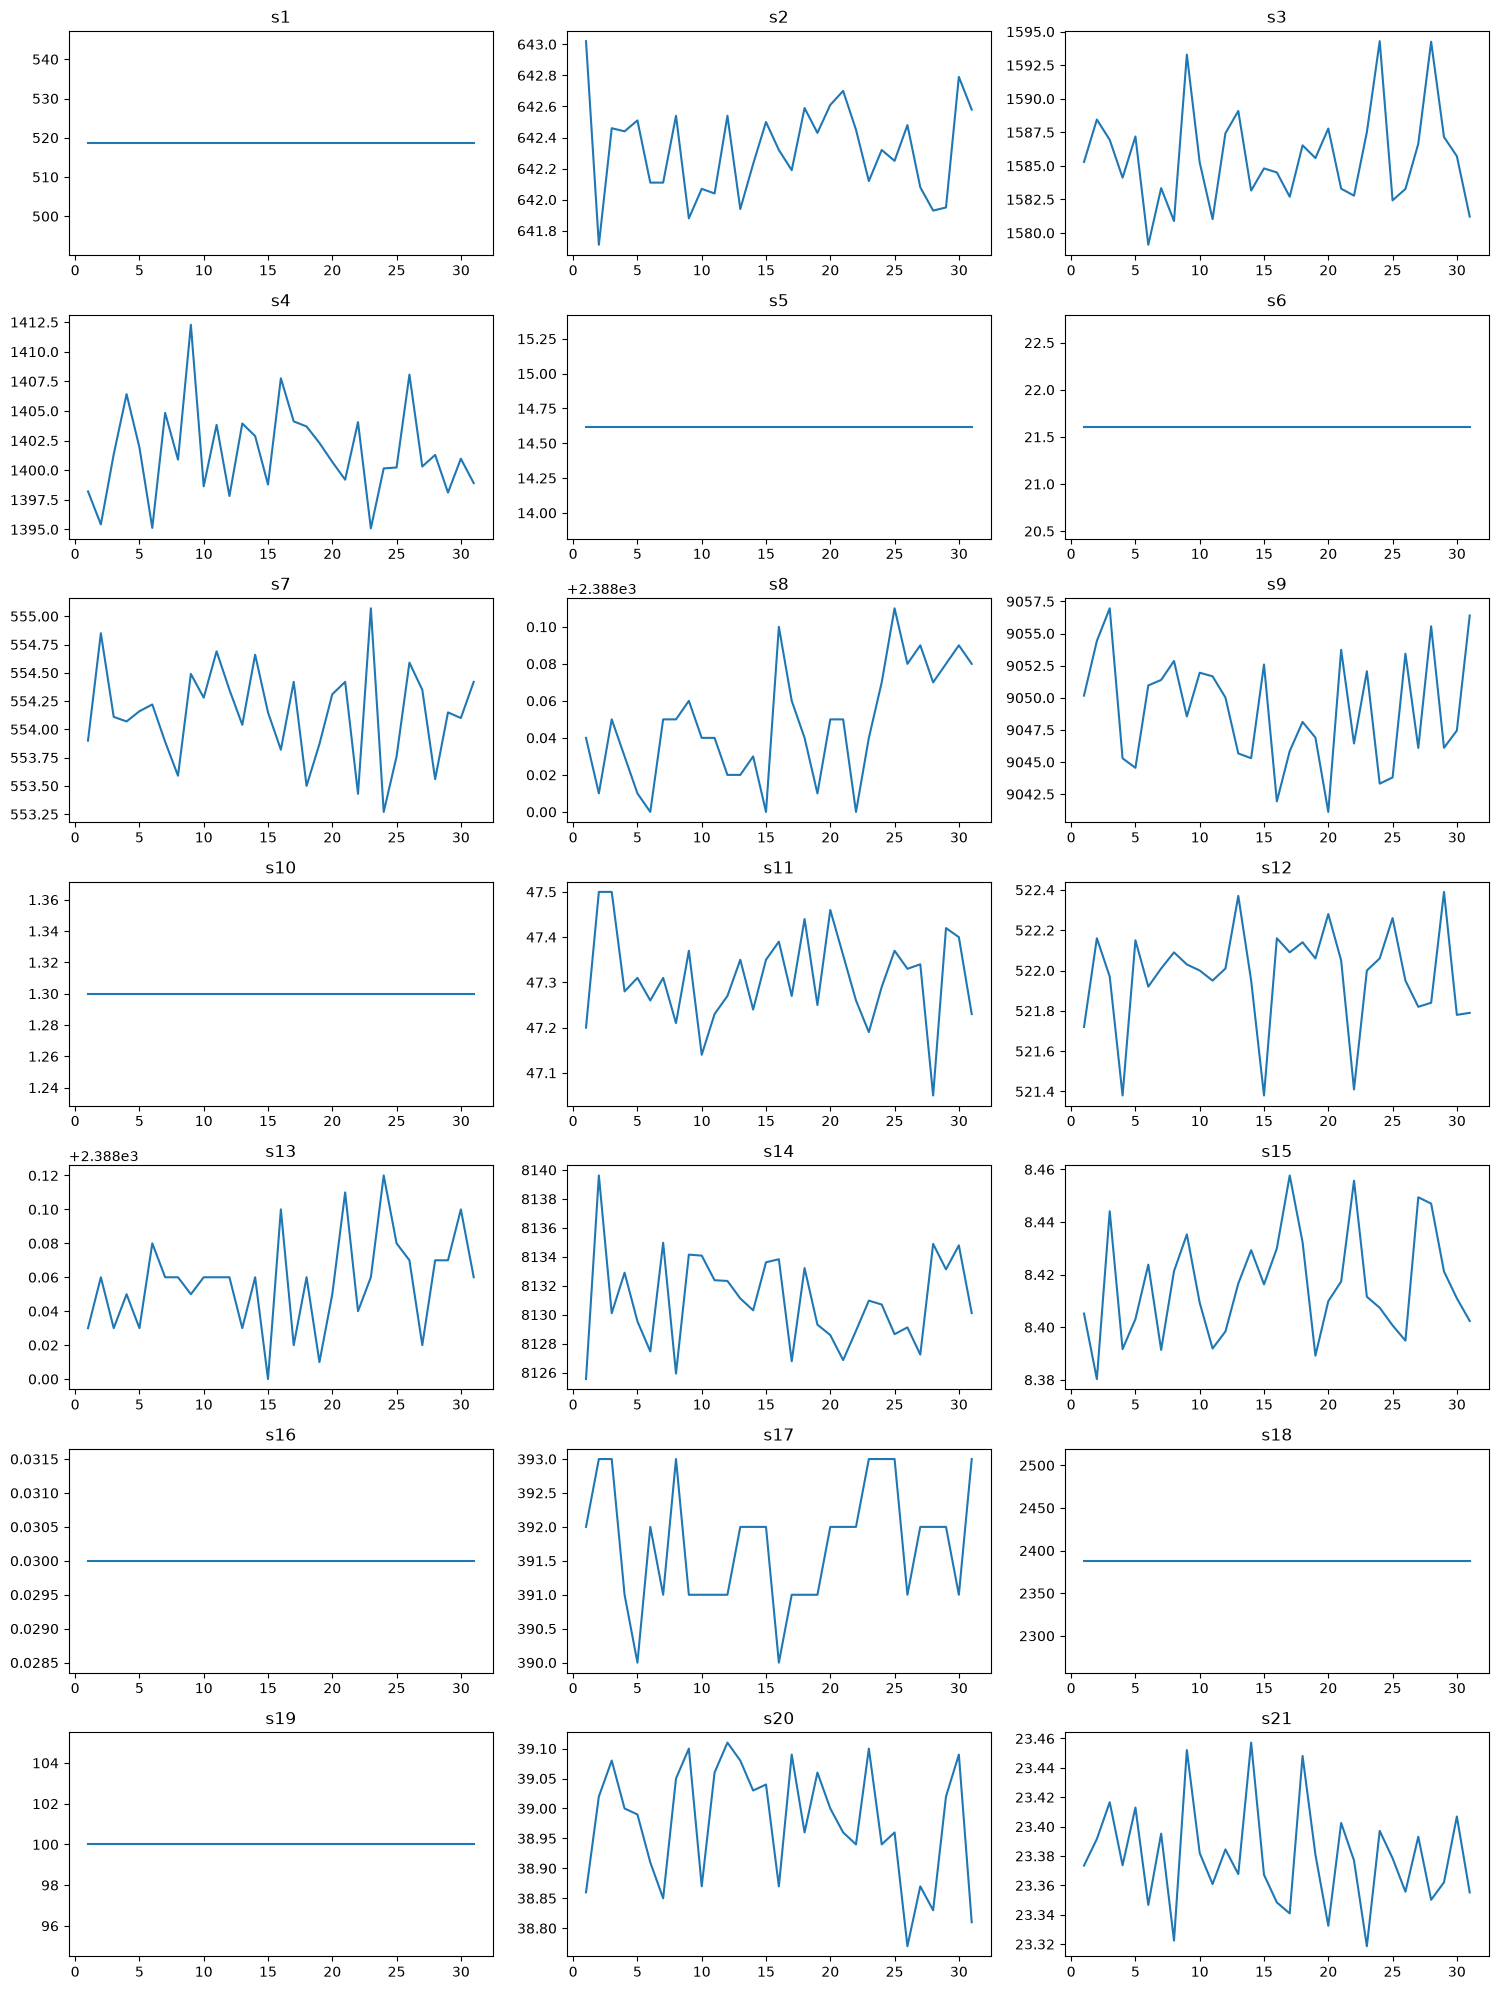

In [53]:
# Plotting graphs for sensor data

test_engine1 = test_df.loc[test_df['unit_number'] == 1]

fig, ax = plt.subplots(7, 3, figsize=(15, 20))  # 7 rows x 3 cols = 21 slots
ax = ax.flatten()  # turns the 2D grid into a flat list so you can index it 0-20


for i, sensor in enumerate(sensor_cols):
    ax[i].plot(test_engine1['time_cycle'], test_engine1[sensor])
    ax[i].set_title(sensor)

plt.tight_layout()  # prevents subplot titles/labels from overlapping
plt.show()

In [54]:
test_df = test_df.drop(columns= sensor_drop)
test_df.head()

,unit_number,time_cycle,op_setting_1,op_setting_2,op_setting_3,s2,s3,s4,s7,s8,s9,s11,s12,s13,s14,s15,s17,s20,s21,max_cycle
0,1,1,0.0023,0.0003,100.0,643.02,1585.29,1398.21,553.90,2388.04,9050.17,47.20,521.72,2388.03,8125.55,8.4052,392,38.86,23.3735,31
1,1,2,-0.0027,-0.0003,100.0,641.71,1588.45,1395.42,554.85,2388.01,9054.42,47.50,522.16,2388.06,8139.62,8.3803,393,39.02,23.3916,31
2,1,3,0.0003,0.0001,100.0,642.46,1586.94,1401.34,554.11,2388.05,9056.96,47.50,521.97,2388.03,8130.10,8.4441,393,39.08,23.4166,31
3,1,4,0.0042,0.0000,100.0,642.44,1584.12,1406.42,554.07,2388.03,9045.29,47.28,521.38,2388.05,8132.90,8.3917,391,39.00,23.3737,31
4,1,5,0.0014,0.0000,100.0,642.51,1587.19,1401.92,554.16,2388.01,9044.55,47.31,522.15,2388.03,8129.54,8.4031,390,38.99,23.4130,31


In [55]:
# Restoring backup
# test_df = raw_test_df.copy()

In [56]:
# Rolling window:
# ===============================

# Getting the  test df after the rolling windows is applied
roll_window_test_df = rolling_window(test_df, sensor_list, 5)

In [57]:
roll_window_test_df.head(10)

,unit_number,time_cycle,op_setting_1,op_setting_2,op_setting_3,s2,s3,s4,s7,s8,...,s14_mean_5,s14_std_5,s15_mean_5,s15_std_5,s17_mean_5,s17_std_5,s20_mean_5,s20_std_5,s21_mean_5,s21_std_5
0,1,1,0.0023,0.0003,100.0,643.02,1585.29,1398.21,553.90,2388.04,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,2,-0.0027,-0.0003,100.0,641.71,1588.45,1395.42,554.85,2388.01,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1,3,0.0003,0.0001,100.0,642.46,1586.94,1401.34,554.11,2388.05,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1,4,0.0042,0.0000,100.0,642.44,1584.12,1406.42,554.07,2388.03,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1,5,0.0014,0.0000,100.0,642.51,1587.19,1401.92,554.16,2388.01,...,8131.542,5.222300,8.40488,0.024080,391.8,1.303840,38.990,0.080623,23.39368,0.020672
5,1,6,0.0012,0.0003,100.0,642.11,1579.12,1395.13,554.22,2388.00,...,8131.924,4.720136,8.40860,0.025534,391.8,1.303840,39.000,0.061237,23.38832,0.029007
6,1,7,-0.0000,0.0002,100.0,642.11,1583.34,1404.84,553.89,2388.05,...,8130.994,2.951437,8.41082,0.022794,391.4,1.140175,38.966,0.088487,23.38904,0.029153
7,1,8,0.0006,-0.0000,100.0,642.54,1580.89,1400.89,553.59,2388.05,...,8130.160,3.748700,8.40626,0.015626,391.4,1.140175,38.960,0.079373,23.37020,0.036422
8,1,9,-0.0036,0.0000,100.0,641.88,1593.29,1412.28,554.49,2388.06,...,8130.410,4.009707,8.41498,0.017520,391.4,1.140175,38.980,0.101489,23.38588,0.051895
9,1,10,-0.0025,-0.0001,100.0,642.07,1585.25,1398.64,554.28,2388.04,...,8131.318,4.269095,8.41622,0.016668,391.6,0.894427,38.956,0.112161,23.37968,0.049648


In [58]:
roll_window_test_df.isna().sum()

unit_number       0
time_cycle        0
op_setting_1      0
op_setting_2      0
op_setting_3      0
s2                0
s3                0
s4                0
s7                0
s8                0
s9                0
s11               0
s12               0
s13               0
s14               0
s15               0
s17               0
s20               0
s21               0
max_cycle         0
s2_mean_5       400
s2_std_5        400
s3_mean_5       400
s3_std_5        400
s4_mean_5       400
s4_std_5        400
s7_mean_5       400
s7_std_5        400
s8_mean_5       400
s8_std_5        400
s9_mean_5       400
s9_std_5        400
s11_mean_5      400
s11_std_5       400
s12_mean_5      400
s12_std_5       400
s13_mean_5      400
s13_std_5       400
s14_mean_5      400
s14_std_5       400
s15_mean_5      400
s15_std_5       400
s17_mean_5      400
s17_std_5       400
s20_mean_5      400
s20_std_5       400
s21_mean_5      400
s21_std_5       400
dtype: int64

In [59]:
# Extracting the max cycles for each engine

test_df = roll_window_test_df[roll_window_test_df['time_cycle'] == roll_window_test_df['max_cycle']]

In [60]:
test_df['unit_number'].values

array([  1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,  13,
        14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,  26,
        27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,  39,
        40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,  52,
        53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,  65,
        66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,  78,
        79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,  91,
        92,  93,  94,  95,  96,  97,  98,  99, 100])

In [61]:
# extracting only test sensor data

test_exclude_sensor = ['unit_number', 'time_cycle', 'op_setting_1', 'op_setting_2', 'op_setting_3', 'max_cycle']

test_sensor_df = test_df.drop(columns=test_exclude_sensor)

In [62]:
# Transforming the sensor data

test_df[test_sensor_df.columns] = scaler.transform(test_sensor_df)
test_df.head()

,unit_number,time_cycle,op_setting_1,op_setting_2,op_setting_3,s2,s3,s4,s7,s8,...,s14_mean_5,s14_std_5,s15_mean_5,s15_std_5,s17_mean_5,s17_std_5,s20_mean_5,s20_std_5,s21_mean_5,s21_std_5
30,1,31,-0.0006,0.0004,100.0,-0.207676,-1.533596,-1.126335,1.207088,-0.240916,...,-0.626148,0.231533,-0.475719,0.322541,-0.941233,-0.550062,0.682381,0.863428,0.899852,-1.576440
79,2,49,0.0018,-0.0001,100.0,-0.267853,-0.651866,0.203126,0.181283,0.041856,...,-0.859582,-1.476187,0.025101,-1.089882,-0.782260,0.616088,0.537395,-0.743375,-0.194926,-1.437832
205,3,126,-0.0016,0.0004,100.0,0.394101,-0.133009,1.102074,-0.878715,0.890172,...,-0.752824,-0.054592,0.537148,1.735756,0.807475,-0.161023,-0.886108,1.444612,-0.528571,-1.878776
311,4,106,0.0012,0.0004,100.0,0.193509,0.651846,-0.237425,-0.821726,0.466014,...,-0.503221,-2.136267,0.323224,0.333378,0.330554,1.355395,-0.411607,0.933244,-0.446429,-1.772224
409,5,98,-0.0013,-0.0004,100.0,-0.829512,-0.101811,1.154494,-0.080867,0.041856,...,-0.799296,-0.987123,-0.150778,-1.351045,0.171581,-1.028680,-0.068912,-0.087433,-0.009445,2.211624


In [63]:
test_df.head()

,unit_number,time_cycle,op_setting_1,op_setting_2,op_setting_3,s2,s3,s4,s7,s8,...,s14_mean_5,s14_std_5,s15_mean_5,s15_std_5,s17_mean_5,s17_std_5,s20_mean_5,s20_std_5,s21_mean_5,s21_std_5
30,1,31,-0.0006,0.0004,100.0,-0.207676,-1.533596,-1.126335,1.207088,-0.240916,...,-0.626148,0.231533,-0.475719,0.322541,-0.941233,-0.550062,0.682381,0.863428,0.899852,-1.576440
79,2,49,0.0018,-0.0001,100.0,-0.267853,-0.651866,0.203126,0.181283,0.041856,...,-0.859582,-1.476187,0.025101,-1.089882,-0.782260,0.616088,0.537395,-0.743375,-0.194926,-1.437832
205,3,126,-0.0016,0.0004,100.0,0.394101,-0.133009,1.102074,-0.878715,0.890172,...,-0.752824,-0.054592,0.537148,1.735756,0.807475,-0.161023,-0.886108,1.444612,-0.528571,-1.878776
311,4,106,0.0012,0.0004,100.0,0.193509,0.651846,-0.237425,-0.821726,0.466014,...,-0.503221,-2.136267,0.323224,0.333378,0.330554,1.355395,-0.411607,0.933244,-0.446429,-1.772224
409,5,98,-0.0013,-0.0004,100.0,-0.829512,-0.101811,1.154494,-0.080867,0.041856,...,-0.799296,-0.987123,-0.150778,-1.351045,0.171581,-1.028680,-0.068912,-0.087433,-0.009445,2.211624


In [64]:
(scaler.feature_names_in_ == X_train_B.columns)

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True])

In [65]:
# model prediction
X_test_A = test_df[X_val_A.columns]

X_test_B = test_df[X_val_B.columns]

X_test_C = test_df[X_train_C.columns]

In [66]:
# Linear Regression
y_pred_test_LR = LR_model_C.predict(X_test_C)

# Random Forest
y_pred_test_RF = RF_model_C.predict(X_test_C)

# XGBoost
y_pred_test_xgb = xgb_model_C.predict(X_test_C)

In [67]:
# Clipping rul_true to 125 cycles to match the training set as the model trained till 125 cycles.

y_test_clipped = rul_true['RUL'].clip(upper = 125)


In [68]:
# Computing RMSE between Predict LR and RF model and clipped true RUL

# LR model
rmse_test_LR = root_mean_squared_error(y_test_clipped, y_pred_test_LR)
print(f"LR RMSE on Test file: {rmse_test_LR:.2f}")

# RF model
rmse_test_RF = root_mean_squared_error(y_test_clipped, y_pred_test_RF)
print(f"RF RMSE on Test file: {rmse_test_RF:.2f}")

# XGBoost model
rmse_test_xgb = root_mean_squared_error(y_test_clipped, y_pred_test_xgb)
print(f"XGB RMSE on Test file: {rmse_test_xgb:.2f}")

LR RMSE on Test file: 20.77
RF RMSE on Test file: 18.52
XGB RMSE on Test file: 17.53


In [69]:
sensors = ["s2","s3","s4","s7","s8","s9","s11","s12","s13","s14","s15","s17","s20","s21"]
rows = df[df["unit_number"] == 1][sensors].head(5)
print(rows.to_dict("records"))

[{'s2': 641.82, 's3': 1589.7, 's4': 1400.6, 's7': 554.36, 's8': 2388.06, 's9': 9046.19, 's11': 47.47, 's12': 521.66, 's13': 2388.02, 's14': 8138.62, 's15': 8.4195, 's17': 392, 's20': 39.06, 's21': 23.419}, {'s2': 642.15, 's3': 1591.82, 's4': 1403.14, 's7': 553.75, 's8': 2388.04, 's9': 9044.07, 's11': 47.49, 's12': 522.28, 's13': 2388.07, 's14': 8131.49, 's15': 8.4318, 's17': 392, 's20': 39.0, 's21': 23.4236}, {'s2': 642.35, 's3': 1587.99, 's4': 1404.2, 's7': 554.26, 's8': 2388.08, 's9': 9052.94, 's11': 47.27, 's12': 522.42, 's13': 2388.03, 's14': 8133.23, 's15': 8.4178, 's17': 390, 's20': 38.95, 's21': 23.3442}, {'s2': 642.35, 's3': 1582.79, 's4': 1401.87, 's7': 554.45, 's8': 2388.11, 's9': 9049.48, 's11': 47.13, 's12': 522.86, 's13': 2388.08, 's14': 8133.83, 's15': 8.3682, 's17': 392, 's20': 38.88, 's21': 23.3739}, {'s2': 642.37, 's3': 1582.85, 's4': 1406.22, 's7': 554.0, 's8': 2388.06, 's9': 9055.15, 's11': 47.28, 's12': 522.19, 's13': 2388.04, 's14': 8133.8, 's15': 8.4294, 's17': 39

In [70]:
df.head()

,unit_number,time_cycle,op_setting_1,op_setting_2,op_setting_3,s2,s3,s4,s7,s8,...,s11,s12,s13,s14,s15,s17,s20,s21,max_cycle,RUL
0,1,1,-0.0007,-0.0004,100.0,641.82,1589.70,1400.60,554.36,2388.06,...,47.47,521.66,2388.02,8138.62,8.4195,392,39.06,23.4190,192,191
1,1,2,0.0019,-0.0003,100.0,642.15,1591.82,1403.14,553.75,2388.04,...,47.49,522.28,2388.07,8131.49,8.4318,392,39.00,23.4236,192,190
2,1,3,-0.0043,0.0003,100.0,642.35,1587.99,1404.20,554.26,2388.08,...,47.27,522.42,2388.03,8133.23,8.4178,390,38.95,23.3442,192,189
3,1,4,0.0007,0.0000,100.0,642.35,1582.79,1401.87,554.45,2388.11,...,47.13,522.86,2388.08,8133.83,8.3682,392,38.88,23.3739,192,188
4,1,5,-0.0019,-0.0002,100.0,642.37,1582.85,1406.22,554.00,2388.06,...,47.28,522.19,2388.04,8133.80,8.4294,393,38.90,23.4044,192,187


# ML Flow
----

In [71]:
import mlflow

In [72]:
mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("cmapss-fd001-rul")

2026/11/04 01:44:42 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/04 01:44:42 INFO mlflow.store.db.utils: Updating database tables
2026/11/04 01:44:44 INFO mlflow.tracking.fluent: Experiment with name 'cmapss-fd001-rul' does not exist. Creating a new experiment.


<Experiment: artifact_location='file:d:/AI_Lab/Projects/NASA_C_MAPSS_RUL_prediction/V2/mlruns/1', creation_time=1793778284164, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1793778284164, lifecycle_stage='active', name='cmapss-fd001-rul', tags={}, trace_location=None, workspace='default'>

In [73]:
def log_run(run_name, model, X_val, y_val, X_test, y_test, feature_set, param_names):
    all_params = model.get_params()
    params = {k: all_params[k] for k in param_names}
    params["model_type"] = type(model).__name__
    params["feature_set"] = feature_set
    with mlflow.start_run(run_name=run_name):
        mlflow.log_params(params)
        val_rmse = root_mean_squared_error(y_val, model.predict(X_val))
        test_rmse = root_mean_squared_error(y_test, model.predict(X_test))
        mlflow.log_metric("val_rmse", val_rmse)
        mlflow.log_metric("test_rmse", test_rmse)
    return val_rmse, test_rmse

In [74]:
sets = {
    "A": ("A:14 raw", X_val_A, y_val_A, X_test_A),
    "B": ("B: 42 raw + rolling", X_val_B, y_val_B, X_test_B),
    "C": ("C: 14 raw + 14 rolling mean", X_val_C, y_val_C, X_test_C)
}

models = {
    "A": (LR_model_A, RF_model_A, xgb_model_A),
    "B": (LR_model_B, RF_model_B, xgb_model_B),
    "C": (LR_model_C, RF_model_C, xgb_model_C)
}

rf_names = ["n_estimators", "max_depth", "random_state"]
xgb_names = ["n_estimators", "learning_rate", "max_depth", "random_state"]

for v, (label, Xv, yv, Xt) in sets.items():
    lr, rf, xgb = models[v]
    
    for tag, m, names in [("lr", lr, []), ("rf", rf, rf_names), ("xgb", xgb, xgb_names)]:
        val, test = log_run(f"{tag}-version-{v}", m, Xv, yv, Xt, y_test_clipped, label, names)
        print(f"{tag}-{v}: val={val:.2f} test={test:.2f}")

lr-A: val=20.39 test=20.72
rf-A: val=17.27 test=16.92
xgb-A: val=17.01 test=17.22
lr-B: val=19.93 test=20.97
rf-B: val=16.70 test=17.74
xgb-B: val=16.44 test=17.69
lr-C: val=19.92 test=20.77
rf-C: val=16.54 test=18.52
xgb-C: val=16.43 test=17.53
